# 05 · Bộ test ngoài (v4): máy tạo ảnh khác họ và công cụ mới

**Vì sao cần.** Bài S4 hiện tại thử với Midjourney và VQDM, nhưng cả hai đều thuộc **họ diffusion**, giống ADM và
SD v1.4 lúc huấn luyện; mọi ảnh GenImage lại có cùng chủ đề ImageNet. Vì vậy S4 (≈0.96) chỉ đo khả năng tổng quát
**trong cùng họ**. Notebook này đo khả năng tổng quát **ra ngoài họ**: ảnh từ FLUX, DALL·E 3, Midjourney v6, GAN...,
và ảnh thật không phải ImageNet.

**Quy trình**

1. Lấy ảnh vào một thư mục: `real/` và mỗi máy tạo ảnh một thư mục con (tải từ Hugging Face bằng
   `scripts/fetch_external.py`, hoặc tự chép vào).
2. Chuẩn hoá **giống hệt GenImage** (224×224 PNG, ảnh AI được nén JPEG theo phân phối chất lượng của ảnh thật).
   `HARMONIZE = False` giữ nguyên định dạng gốc: gần với ảnh mà web demo nhận.
3. Trích embedding CLIP/DINOv2 và tạo bundle cho bộ ảnh mới (**cần GPU**, như notebook 02).
4. Chấm điểm AEGIS, 3 chuyên gia và 3 mô hình học máy (huấn luyện trên GenImage, không học thêm gì), so với S4 cùng họ.

Nếu chưa có dữ liệu thật, notebook chạy ở **demo mode** với ảnh tổng hợp (số liệu không có ý nghĩa).

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

from src.core.config import load_config
from src.core.contracts import SplitManifest

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
cfg = load_config()
print("repo:", ROOT)

repo: c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics


In [2]:
# Bộ dữ liệu thật (GenImage đã chuẩn hoá). Nếu chưa có, notebook tự chuyển sang DEMO MODE:
# ảnh tổng hợp + embedding giả lập, chạy trên CPU trong ~1 phút. Số liệu DEMO không có ý nghĩa khoa học.
MANIFEST = ROOT / "data/normalized_v2/manifest.json"
DEMO = not MANIFEST.exists()
if DEMO:
    from src.models.demo_features import build_demo
    cfg, man = build_demo(ROOT / "data/demo", scale=6, cfg=cfg)
    MANIFEST = ROOT / "data/demo/images/manifest.json"
else:
    man = SplitManifest.load(MANIFEST)
print("DEMO MODE" if DEMO else "REAL DATA", "|", len(man.records), "records |", MANIFEST)

REAL DATA | 32170 records | c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\normalized_v2\manifest.json


In [3]:
import subprocess
from src.data.external import default_out, ingest_external, split_name
from src.evaluation.external_eval import check_ready, evaluate_external, external_bundle_path, summary_lines
from src.evaluation.ml_comparison import DEEP_METHODS, DEEP_SET, FEATURE_SETS, HEAD_VARIANTS
from src.learning.classic_models import DEFAULT_MODELS

EXT_NAME = "newgen"                       # tên ngắn của bộ test ngoài (split sẽ là ext_<tên>)
EXT_RAW = ROOT / "data/raw/external" / EXT_NAME   # thư mục real/ + <generator>/
HARMONIZE = True                          # False: giữ định dạng gốc của ảnh AI (thiết lập "web")
REAL_FROM_MAIN = False                    # True nếu bộ ngoài không có ảnh thật (vd. Synthbuster)
MAX_PER_GENERATOR = None                  # vd. 500 để chạy nhanh

FETCH = False                             # True: tải từ Hugging Face (cần: pip install datasets)
HF_DATASET = "Robo531/ai-detector-benchmark-test-data"   # kiểm tra giấy phép của bộ dữ liệu trước khi dùng
HF_SPLIT, HF_GENERATOR_COLUMN = "train", "generator"

HEADS = list(HEAD_VARIANTS)
FEATURES = list(FEATURE_SETS)
MODELS = list(DEFAULT_MODELS)
DEVICE = "cuda" if __import__("torch").cuda.is_available() else "cpu"
B = 200 if DEMO else 1000
OUT = ROOT / "reports" / ("demo_external" if DEMO else "external") / (EXT_NAME if HARMONIZE else EXT_NAME + "_raw")

## 1. Lấy ảnh

In [4]:
if DEMO:
    from src.models.demo_features import build_demo_external_raw
    EXT_RAW = build_demo_external_raw(ROOT / "data/demo/raw_external" / EXT_NAME)
elif FETCH:
    subprocess.run([sys.executable, "scripts/fetch_external.py", "--dataset", HF_DATASET, "--split", HF_SPLIT,
                    "--out", str(EXT_RAW), "--generator-column", HF_GENERATOR_COLUMN], check=True)
print({d.name: sum(1 for _ in d.rglob("*") if _.is_file()) for d in sorted(Path(EXT_RAW).iterdir()) if d.is_dir()})

{'flux': 48, 'imagegbt': 42, 'nano': 45, 'real': 384, 'sdxl': 42, 'seedream': 41}


## 2. Chuẩn hoá giống GenImage

In [5]:
ext_dir = (ROOT / "data/demo/external" / EXT_NAME) if DEMO else default_out(cfg, EXT_NAME, HARMONIZE)
ext = ingest_external(EXT_RAW, ext_dir, EXT_NAME, cfg, harmonize=HARMONIZE, max_per_generator=MAX_PER_GENERATOR)
display(pd.crosstab(pd.Series([r.generator for r in ext.records], name="generator"),
                    pd.Series(["AI" if r.label else "Real" for r in ext.records], name="nhãn")))

2026-11-25 21:21:34,923 | INFO    | aegis.src.data.external | external set 'newgen' (harmonised): 560 images {'flux': 41, 'imagegbt': 37, 'nano': 38, 'real': 368, 'sdxl': 38, 'seedream': 38}, 42 skipped -> C:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\external\newgen\manifest.json


nhãn,AI,Real
generator,,
flux,41,0
imagegbt,37,0
nano,38,0
real,0,368
sdxl,38,0
seedream,38,0


## 3. Trích embedding và tạo bundle (cần GPU)

Giống notebook 02 nhưng chỉ cho ảnh của bộ test ngoài; các head đã huấn luyện được dùng lại, **không học thêm gì**.

In [6]:
if DEMO:
    from src.models.demo_features import build_demo_external
    build_demo_external(cfg, man, ext)
else:
    from src.models.bundle import main as bundle_main
    from src.models.extract import main as extract_main
    mpath, split = str(ext_dir / "manifest.json"), split_name(EXT_NAME)
    for expert in ("clip", "dinov2"):
        extract_main(["--manifest", mpath, "--expert", expert, "--splits", split, "--device", DEVICE])
    for hv in HEADS:
        bundle_main(["--manifest", mpath, "--split", split, "--head-variant", hv, "--device", DEVICE,
                     "--out", str(external_bundle_path(cfg, split, hv))])
print("còn thiếu:", check_ready(cfg, ext, HEADS, FEATURES) or "không, sẵn sàng")

2026-11-25 21:21:43,590 | INFO    | aegis.src.models.extract | clip: 560 records, 560 to extract
W1125 21:22:25.172000 28864 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

2026-11-25 21:22:53,664 | INFO    | aegis.src.models.clip_expert | loaded CLIP openai/clip-vit-large-patch14 (feature_dim=768)
2026-11-25 21:23:29,133 | INFO    | aegis.src.models.extract | dinov2: 560 records, 560 to extract


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

2026-11-25 21:23:31,318 | INFO    | aegis.src.models.dinov2_expert | loaded DINOv2 facebook/dinov2-base (feature_dim=768)
2026-11-25 21:24:03,705 | INFO    | aegis.src.models.bundle | bundle ext_newgen: 560 samples -> C:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\cache\bundles\clean\ext_newgen.pt
2026-11-25 21:24:23,750 | INFO    | aegis.src.models.bundle | bundle ext_newgen: 560 samples -> C:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\cache\bundles\aug\ext_newgen.pt


còn thiếu: không, sẵn sàng


## 4. Chấm điểm

In [7]:
out = evaluate_external(cfg, man, ext, HEADS, FEATURES, MODELS, real_from_main=REAL_FROM_MAIN, B=B, out_dir=OUT)
res = pd.DataFrame(out["results"])
res["method"] = np.where(res.group == "deep", res.model, res.model + " · " + res.feature_set)
DEEP = list(DEEP_METHODS)
order = DEEP + [f"{m} · {f}" for f in FEATURES for m in MODELS]
tab = res.pivot_table(index=["head_variant", "method"], columns="generator", values="auroc")
gens = [g for g in tab.columns if g != "all"] + ["all"]
display(tab[gens].reindex(order, level="method").style.format("{:.3f}").background_gradient(axis=None, cmap="RdYlGn"))

2026-11-25 21:24:59,393 | INFO    | aegis.src.data.handcrafted | handcrafted features: computing 560 images (32170 already cached)
2026-11-25 21:25:15,987 | INFO    | aegis.src.data.handcrafted | handcrafted features: 560/560 (17s)
2026-11-25 21:25:16,145 | INFO    | aegis.src.learning.bundle_io | loaded bundle ext_newgen.pt (n=560)
2026-11-25 21:25:16,295 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-25 21:25:16,306 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 2.3774, 'dinov2': 1.7704, 'freq': 6.4604}
2026-11-25 21:25:21,624 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.4706 -> 0.3733
2026-11-25 21:25:28,541 | INFO    | aegis.src.data.handcrafted | handcrafted features: all 32730 records cached (C:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\cache\features\handcrafted_hc1.pt)
2026-11-25 21:25:42,179 | INFO    | aegis.src.learning.classic_models | rbf_svm   

## 5. Cùng họ so với khác họ

So sánh AUROC trên ảnh sạch (S1), trên generator chưa thấy **cùng họ** (S4 của notebook 04) và trên bộ test ngoài
(**khác họ / công cụ mới**). Cần chạy notebook 04 trước để có `reports/ml_comparison/results.csv`.

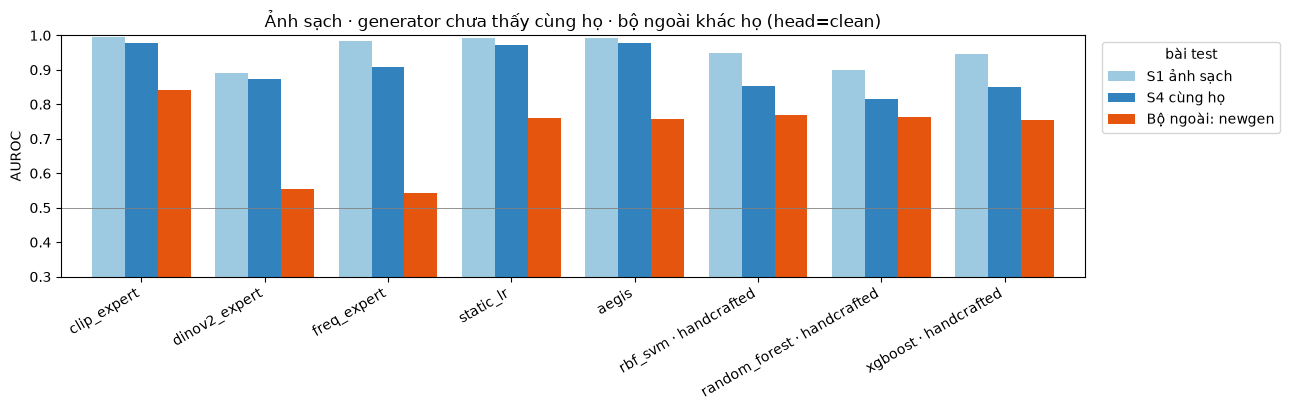

In [8]:
ref_csv = ROOT / ("reports/demo_ml_comparison" if DEMO else "reports/ml_comparison") / "results.csv"
if ref_csv.exists():
    r4 = pd.read_csv(ref_csv)
    r4 = r4[((r4.scenario == "S1") & (r4.level == "clean")) | ((r4.scenario == "S4") & (r4.generator == "all"))]
    r4["method"] = np.where(r4.group == "deep", r4.model, r4.model + " · " + r4.feature_set)
    r4["bài test"] = np.where(r4.scenario == "S1", "S1 ảnh sạch", "S4 cùng họ")
    ex = res[res.generator == "all"].assign(**{"bài test": f"Bộ ngoài: {EXT_NAME}"})
    both = pd.concat([r4[["head_variant", "method", "bài test", "auroc"]], ex[["head_variant", "method", "bài test", "auroc"]]])
    cmp = both.pivot_table(index=["head_variant", "method"], columns="bài test", values="auroc")
    cols = ["S1 ảnh sạch", "S4 cùng họ", f"Bộ ngoài: {EXT_NAME}"]
    cmp = cmp[[c for c in cols if c in cmp.columns]].reindex(order, level="method")
    cmp["khác họ − cùng họ"] = cmp.iloc[:, -1] - cmp["S4 cùng họ"]
    display(cmp.style.format("{:+.3f}", subset=["khác họ − cùng họ"]).format("{:.3f}", subset=cols[:len(cmp.columns) - 1]))
    HV = HEADS[0]
    show = [m for m in order if m in DEEP or m.endswith("· handcrafted")]
    piv = cmp.loc[HV].reindex(show)[[c for c in cols if c in cmp.columns]]
    ax = piv.plot.bar(figsize=(13, 4.2), width=0.8, color=["#9ecae1", "#3182bd", "#e6550d"])
    ax.set_ylim(0.3, 1.0); ax.axhline(0.5, color="gray", lw=0.6); ax.set_ylabel("AUROC"); ax.set_xlabel("")
    ax.set_title(f"Ảnh sạch · generator chưa thấy cùng họ · bộ ngoài khác họ (head={HV})")
    ax.legend(title="bài test", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
else:
    print("Chưa có", ref_csv, "- chạy notebook 04 trước.")

## 6. Gợi ý viết báo cáo

* **Câu hỏi chính:** AUROC giảm bao nhiêu khi chuyển từ "chưa thấy, cùng họ" (S4) sang "chưa thấy, khác họ" (bộ
  ngoài)? Mức giảm đó là con số trung thực về khả năng tổng quát của hệ thống.
* Máy tạo ảnh nào khó nhất? Vì sao (khác họ, ảnh độ phân giải cao, phong cách khác ImageNet...)?
* AEGIS còn hơn từng chuyên gia không? Gating có giúp khi cả ba chuyên gia đều chưa từng thấy loại ảnh này?
* Học máy trên đặc trưng thủ công so với học sâu: bên nào sụp nhiều hơn khi gặp họ mới?
* `HARMONIZE = False` (định dạng gốc) có làm kết quả tụt thêm không? Điều đó giải thích web demo chỉ đúng 40%
  với ảnh Midjourney gốc như thế nào?
* Nếu dùng `REAL_FROM_MAIN = True`, ghi rõ ảnh thật vẫn là ImageNet: kết quả chỉ đo phía ảnh AI.